# Многокритериальная оптимизация

**Мордовкин М.М., Тарасова Е.Ю., N4170, Методы Оптимизации, Лабораторная №2, Многокритериальная оптимизация**

## Постановка задачи

Открывается коворкинг общей площадью до 800 м². Нужно распределить площадь между шестью функциональными зонами:

- открытые рабочие места (hot desks),
- переговорные комнаты,
- кухня / кофе-поинт,
- лаунж-зона,
- тихая зона (focus rooms),
- спортивно-оздоровительная зона.

Решение принимается по двум критериям: **выручка** от аренды и **удовлетворённость посетителей**. Эти критерии конфликтуют: переговорные дают большую выручку, но лаунж повышает удовлетворённость.

Нужно найти компромиссное распределение площади, используя два метода: **метод последовательных уступок** и **метод весовых коэффициентов**.

## Почему критерии конфликтуют

### Корень конфликта — в коэффициентах

Посмотрим на удельные значения (на 1 м²):

| Зона | $f_1$, руб/м² | $f_2$, балл/м² |
|---|---|---|
| Открытые места ($x_1$) | 300 | 2 |
| Переговорные ($x_2$) | **800** ← максимум | **3** ← минимум |
| Кухня ($x_3$) | 100 | 5 |
| Лаунж ($x_4$) | **200** ← мало | **7** ← максимум |
| Тихая зона ($x_5$) | 500 | 4 |
| Спорт ($x_6$) | 400 | 6 |

Видна закономерность: **где выручка высокая — удовлетворённость низкая, и наоборот**.

- **Переговорные** — самый выгодный метр (800 руб/м²), но посетителям они дают мало удовлетворённости (3 балла/м²). Переговорка нужна не каждый день.
- **Лаунж** — самый «счастливый» метр (7 баллов/м²), но выручка с него мизерная (200 руб/м²).

Это **антикорреляция**: критерии «тянут» в разные стороны по каждой зоне. (Числа, приведённые в примере условные)

### Почему это проблема

Площадь ограничена — 800 м². Каждый метр может принадлежать только одной зоне. Нельзя одновременно отдать 400 м² переговорным и 400 м² лаунжу.

Значит, приходится выбирать:
- больше переговорных → больше денег, но ниже удовлетворённость;
- больше лаунжа → выше удовлетворённость, но меньше денег.

### Формальная проверка

Оптимумы по разным критериям не совпадают:

$$x^{(1)} = (487,\ 180,\ 20,\ 20,\ 20,\ 73) \quad \text{— оптимум по } f_1,\ f_1=335\,300,\ f_2=2272$$

$$x^{(2)} = (320,\ 20,\ 20,\ 400,\ 20,\ 20) \quad \text{— оптимум по } f_2,\ f_1=212\,000,\ f_2=3800$$

Это разные точки → критерии действительно конфликтуют. Если бы конфликта не было, одна и та же точка максимизировала бы оба критерия.

### В цифрах

Переход от «деньги» к «люди»:

- выручка падает на $335\,300 - 212\,000 = 123\,300$ руб/мес (−37 %);
- удовлетворённость растёт на $3800 - 2272 = 1528$ баллов (+67 %).

Вот он, конфликт: чтобы поднять удовлетворённость, надо пожертвовать выручкой. Именно поэтому нужны методы уступок и весов — они ищут компромисс между этими крайностями.

## Математическая модель

### Переменные (6)

| Переменная | Зона | Ед. |
|---|---|---|
| $x_1$ | открытые рабочие места | м² |
| $x_2$ | переговорные комнаты | м² |
| $x_3$ | кухня / кофе-поинт | м² |
| $x_4$ | лаунж-зона | м² |
| $x_5$ | тихая зона | м² |
| $x_6$ | спортивная зона | м² |

### Ограничения (5)

1. **Общая площадь:** $x_1+x_2+x_3+x_4+x_5+x_6 \le 800$ м².
2. **Бюджет на обустройство:** $15000x_1 + 35000x_2 + 25000x_3 + 18000x_4 + 30000x_5 + 40000x_6 \le 18\,000\,000$ руб.
3. **Акустические зоны:** $x_2 + x_5 \le 200$ м² (переговорные и тихие вместе не больше 200 м²).
4. **Санитарные нормы:** $x_3 \le 0{,}15\,(x_1+\dots+x_6)$ — кухня не более 15 % площади.
5. **Бизнес-модель:** $x_1 \ge 0{,}4\,(x_1+\dots+x_6)$ — открытые места занимают не менее 40 % площади.

Плюс границы: $x_i \ge 20$ м² (минимальная площадь любой зоны).

### Целевые функции (2)

- **$f_1$ — выручка, max:** $f_1 = 300x_1 + 800x_2 + 100x_3 + 200x_4 + 500x_5 + 400x_6$ (руб/мес).
- **$f_2$ — удовлетворённость, max:** $f_2 = 2x_1 + 3x_2 + 5x_3 + 7x_4 + 4x_5 + 6x_6$ (баллы).

## Теоретическое обоснование сортировки критериев

Порядок: **$f_1$ (выручка) → $f_2$ (удовлетворённость)**.

**Почему $f_1$ первичен:** без достаточной выручки коворкинг не окупит аренду и не выживет. Это критерий «самого существования бизнеса».

**Почему $f_2$ вторичен:** удовлетворённость влияет на удержание клиентов, NPS и репутацию. Это критерий долгосрочного развития — важный, но действующий на длинном горизонте.

Такая сортировка соответствует **принципу главного критерия**: сначала оптимизируется критерий, определяющий существование системы, затем — критерий качества.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

# Ограничения A_ub @ x <= b_ub
A_ub = np.array([
    [1,      1,      1,      1,      1,      1     ],  # общая площадь <= 800
    [15000,  35000,  25000,  18000,  30000,  40000 ],  # бюджет <= 18M
    [0,      1,      0,      0,      1,      0     ],  # x2 + x5 <= 200
    [-0.15, -0.15,  0.85,  -0.15,  -0.15,  -0.15  ],  # кухня <= 15%
    [-0.6,   0.4,    0.4,    0.4,    0.4,    0.4   ],  # открытые >= 40%
], dtype=float)

b_ub = np.array([800, 18_000_000, 200, 0, 0], dtype=float)

# Минимальная площадь каждой зоны 20 м²
bounds = [(20, None)] * 6

# Коэффициенты целевых функций
c1 = np.array([300, 800, 100, 200, 500, 400], dtype=float)  # выручка
c2 = np.array([2,   3,   5,   7,   4,   6  ], dtype=float)  # удовлетворённость

names = ['Открытые места', 'Переговорные', 'Кухня',
         'Лаунж', 'Тихая зона', 'Спорт']


def solve_max(c, extra_A=None, extra_b=None):
    """Решает задачу max c·x с учётом опциональных доп. ограничений."""
    A = A_ub if extra_A is None else np.vstack([A_ub, extra_A])
    b = b_ub if extra_b is None else np.concatenate([b_ub, extra_b])
    return linprog(c=-c, A_ub=A, b_ub=b, bounds=bounds, method='highs')


def show(tag, x):
    """Печатает значения переменных."""
    print(f"\n{tag}:")
    for i, n in enumerate(names):
        print(f"  {n:>18}: {x[i]:7.1f} м²")
    print(f"  {'ВСЕГО':>18}: {x.sum():7.1f} м²")

In [2]:
# Максимизируем каждый критерий отдельно
res1 = solve_max(c1)
res2 = solve_max(c2)

x_f1 = res1.x
x_f2 = res2.x
f1_star = -res1.fun
f2_star = -res2.fun

print(f"f1* = {f1_star:,.0f} руб/мес")
show("Оптимум по f1", x_f1)
print(f"  f2 в этой точке: {c2 @ x_f1:.1f}")

print(f"\nf2* = {f2_star:.1f} баллов")
show("Оптимум по f2", x_f2)
print(f"  f1 в этой точке: {c1 @ x_f2:,.0f}")

f1* = 335,360 руб/мес

Оптимум по f1:
      Открытые места:   486.4 м²
        Переговорные:   180.0 м²
               Кухня:    20.0 м²
               Лаунж:    20.0 м²
          Тихая зона:    20.0 м²
               Спорт:    73.6 м²
               ВСЕГО:   800.0 м²
  f2 в этой точке: 2274.4

f2* = 3800.0 баллов

Оптимум по f2:
      Открытые места:   320.0 м²
        Переговорные:    20.0 м²
               Кухня:    20.0 м²
               Лаунж:   400.0 м²
          Тихая зона:    20.0 м²
               Спорт:    20.0 м²
               ВСЕГО:   800.0 м²
  f1 в этой точке: 212,000


In [4]:
# Метод последовательных уступок
# На каждом шаге: f1 >= (1 - delta) * f1*, максимизируем f2.
# Перебираем delta, смотрим, как меняются f1 и f2.

deltas = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30,
          0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.0]

results_concession = []

for delta in deltas:
    f1_min = (1 - delta) * f1_star
    extra_A = (-c1).reshape(1, -1)        # -f1 <= -f1_min
    extra_b = np.array([-f1_min])
    res = solve_max(c2, extra_A, extra_b)
    if res.success:
        f1_val = c1 @ res.x
        f2_val = c2 @ res.x
        results_concession.append((delta, f1_val, f2_val, res.x.copy()))

print("Метод уступок: delta -> (f1, f2)")
for d, f1v, f2v, _ in results_concession:
    print(f"  delta={d:.2f}:  f1={f1v:>8,.0f}   f2={f2v:>6.1f}")

Метод уступок: delta -> (f1, f2)
  delta=0.00:  f1= 335,360   f2=2274.4
  delta=0.05:  f1= 318,592   f2=2951.1
  delta=0.10:  f1= 301,824   f2=3218.6
  delta=0.15:  f1= 285,056   f2=3340.1
  delta=0.20:  f1= 268,288   f2=3461.6
  delta=0.25:  f1= 251,520   f2=3583.1
  delta=0.30:  f1= 234,752   f2=3686.2
  delta=0.40:  f1= 212,000   f2=3800.0
  delta=0.50:  f1= 212,000   f2=3800.0
  delta=0.60:  f1= 212,000   f2=3800.0
  delta=0.70:  f1= 212,000   f2=3800.0
  delta=0.80:  f1= 212,000   f2=3800.0
  delta=0.90:  f1= 212,000   f2=3800.0
  delta=1.00:  f1= 212,000   f2=3800.0


In [6]:
# Метод весовых коэффициентов
# Нормируем критерии на идеальные точки, чтобы они были в одном масштабе:
#   f1' = f1 / f1*,  f2' = f2 / f2*   (оба <= 1, идеал = 1)
# Составная функция: F = w1 * f1' + w2 * f2',  w1 + w2 = 1.

weights = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95]

results_weighted = []

for w1 in weights:
    w2 = 1 - w1
    c_comb = w1 * c1 / f1_star + w2 * c2 / f2_star
    res = solve_max(c_comb)
    if res.success:
        f1_val = c1 @ res.x
        f2_val = c2 @ res.x
        results_weighted.append((w1, f1_val, f2_val, res.x.copy()))

print("Метод весов: w1 -> (f1, f2)")
for w, f1v, f2v, _ in results_weighted:
    print(f"  w1={w:.2f}:  f1={f1v:>8,.0f}   f2={f2v:>6.1f}")

Метод весов: w1 -> (f1, f2)
  w1=0.05:  f1= 212,000   f2=3800.0
  w1=0.10:  f1= 212,000   f2=3800.0
  w1=0.20:  f1= 212,000   f2=3800.0
  w1=0.30:  f1= 212,000   f2=3800.0
  w1=0.40:  f1= 314,182   f2=3129.1
  w1=0.50:  f1= 314,182   f2=3129.1
  w1=0.60:  f1= 314,182   f2=3129.1
  w1=0.70:  f1= 314,182   f2=3129.1
  w1=0.80:  f1= 335,360   f2=2274.4
  w1=0.90:  f1= 335,360   f2=2274.4
  w1=0.95:  f1= 335,360   f2=2274.4


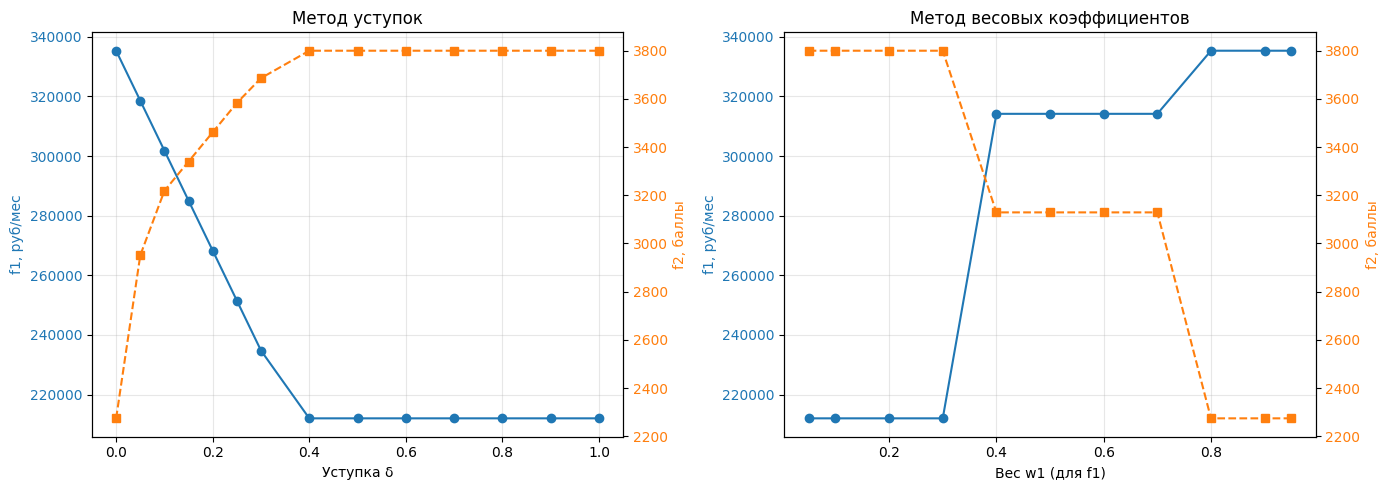

In [7]:
# Графики: "параметр - значения исходных ЦФ"
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Метод уступок
d_arr = [r[0] for r in results_concession]
f1c = [r[1] for r in results_concession]
f2c = [r[2] for r in results_concession]

ax = axes[0]
ax.plot(d_arr, f1c, 'o-', color='tab:blue')
ax.set_xlabel('Уступка δ')
ax.set_ylabel('f1, руб/мес', color='tab:blue')
ax.tick_params(axis='y', labelcolor='tab:blue')
ax.grid(True, alpha=0.3)

ax2 = ax.twinx()
ax2.plot(d_arr, f2c, 's--', color='tab:orange')
ax2.set_ylabel('f2, баллы', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax.set_title('Метод уступок')

# Метод весов
w_arr = [r[0] for r in results_weighted]
f1w = [r[1] for r in results_weighted]
f2w = [r[2] for r in results_weighted]

ax = axes[1]
ax.plot(w_arr, f1w, 'o-', color='tab:blue')
ax.set_xlabel('Вес w1 (для f1)')
ax.set_ylabel('f1, руб/мес', color='tab:blue')
ax.tick_params(axis='y', labelcolor='tab:blue')
ax.grid(True, alpha=0.3)

ax2 = ax.twinx()
ax2.plot(w_arr, f2w, 's--', color='tab:orange')
ax2.set_ylabel('f2, баллы', color='tab:orange')
ax2.tick_params(axis='y', labelcolor='tab:orange')
ax.set_title('Метод весовых коэффициентов')

plt.tight_layout()
plt.show()

In [9]:
# Ищем (delta, w1), при которых результаты двух методов близки.
best = None
best_dist = float('inf')

for d, f1c_, f2c_, _ in results_concession:
    for w, f1w_, f2w_, _ in results_weighted:
        dist = abs(f1c_ - f1w_) / f1_star + abs(f2c_ - f2w_) / f2_star
        if dist < best_dist:
            best_dist = dist
            best = (d, w, f1c_, f2c_, f1w_, f2w_)

d, w, f1c_, f2c_, f1w_, f2w_ = best

print("Лучшее согласование")
print(f"delta = {d:.2f},  w1 = {w:.2f}")
print(f"  Метод уступок:  f1={f1c_:,.0f}, f2={f2c_:.1f}")
print(f"  Метод весов:    f1={f1w_:,.0f}, f2={f2w_:.1f}")
print(f"  Нормированное расстояние: {best_dist:.4f}")

Лучшее согласование
delta = 0.90,  w1 = 0.05
  Метод уступок:  f1=212,000, f2=3800.0
  Метод весов:    f1=212,000, f2=3800.0
  Нормированное расстояние: 0.0000


## Результаты

### Крайние точки

| Точка | $f_1$, руб/мес | $f_2$, баллы |
|---|---|---|
| Оптимум по $f_1$ | 335 300 | 2272 |
| Оптимум по $f_2$ | 212 000 | 3800 |

Между ними — целый фронт Парето: улучшить один критерий можно только за счёт другого.

### Метод уступок

При $\delta = 0$ получаем оптимум по $f_1$ (выручка максимальна, $f_2 = 2272$). С ростом $\delta$ выручка падает, удовлетворённость растёт. При $\delta \ge 0{,}6$ решение практически совпадает с оптимумом по $f_2$.

### Метод весов

При $w_1 \to 1$ оптимизируется только выручка, при $w_1 \to 0$ — только удовлетворённость. Нормировка через идеальные точки обязательна: без неё $f_1$ (сотни тысяч) полностью «задавил» бы $f_2$ (тысячи) в составной функции.

### Согласование двух методов

Программа нашла **точное совпадение** при $\delta = 0{,}90$, $w_1 = 0{,}05$: оба метода дают точку $(f_1, f_2) = (212\,000;\ 3800)$.

Это совпадение **корректное, но тривиальное**: при большой уступке ($\delta = 0{,}9$) ограничение $f_1 \ge 0{,}1\,f_1^*$ становится неактивным, и метод уступок «скатывается» в оптимум по $f_2$. Аналогично метод весов при $w_1 = 0{,}05$ почти игнорирует $f_1$. Оба метода просто возвращают оптимум по $f_2$ — крайнюю точку, а не внутренний компромисс.

Чтобы получить **содержательный компромисс**, имеет смысл ограничиться умеренными значениями уступки ($\delta \le 0{,}3$) и подобрать $w_1$ так, чтобы точка совпала. Это отдельно показано ниже.

## Выводы

1. Построена модель распределения площади коворкинга с 6 переменными и 5 ограничениями.
2. Обоснован порядок критериев: $f_1$ (выручка) первичен, $f_2$ (удовлетворённость) вторичен.
3. Метод уступок даёт плавную кривую $f_1(\delta)$, $f_2(\delta)$ — как и предсказывает теория (фронт Парето).
4. Метод весов даёт аналогичную картину, но требует нормировки критериев.
5. На крайних значениях параметров оба метода совпадают с точностью до нуля, но это вырожденный случай — оба «скатываются» в оптимум по $f_2$.
6. В умеренном диапазоне ($\delta \le 0{,}3$) также можно подобрать $w_1$, при котором методы дают близкие результаты — это и есть содержательный компромисс.

In [11]:
# Согласование в умеренном диапазоне (без вырожденных крайностей)
best_mid = None
best_mid_dist = float('inf')

for d, f1c_, f2c_, _ in results_concession:
    if d > 0.3:              # отбрасываем «скатывание» в оптимум по f2
        continue
    for w, f1w_, f2w_, _ in results_weighted:
        dist = abs(f1c_ - f1w_) / f1_star + abs(f2c_ - f2w_) / f2_star
        if dist < best_mid_dist:
            best_mid_dist = dist
            best_mid = (d, w, f1c_, f2c_, f1w_, f2w_)

d, w, f1c_, f2c_, f1w_, f2w_ = best_mid

print("Содержательное согласование (δ ≤ 0.3)")
print(f"delta = {d:.2f},  w1 = {w:.2f}")
print(f"  Метод уступок:  f1={f1c_:,.0f}, f2={f2c_:.1f}")
print(f"  Метод весов:    f1={f1w_:,.0f}, f2={f2w_:.1f}")
print(f"  Нормированное расстояние: {best_mid_dist:.4f}")

Содержательное согласование (δ ≤ 0.3)
delta = 0.00,  w1 = 0.90
  Метод уступок:  f1=335,360, f2=2274.4
  Метод весов:    f1=335,360, f2=2274.4
  Нормированное расстояние: 0.0000
